In [3]:
# import the libraries as shown below

from tensorflow.keras.layers import Input, Lambda, Dense, Flatten
from tensorflow.keras.models import Model
from tensorflow.keras.applications.inception_v3 import InceptionV3
#from keras.applications.vgg16 import VGG16
from tensorflow.keras.applications.inception_v3 import preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import load_img

from tensorflow.keras.preprocessing.image import ImageDataGenerator,load_img
from tensorflow.keras.models import Sequential
import numpy as np
import pandas as pd
from glob import glob
import matplotlib.pyplot as plt

In [4]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns # Load the CSV file containing labels
labels_df = pd.read_csv('trainLabels.csv')

# dataset
**Link**----->>>>>https://www.kaggle.com/datasets/tanlikesmath/diabetic-retinopathy-resized

**link** --->>>  https://www.kaggle.com/competitions/aptos2019-blindness-detection

In [5]:
labels_df

,image,level
0,10_left,0
1,10_right,0
2,13_left,0
3,13_right,0
4,15_left,1
...,...,...
35121,44347_right,0
35122,44348_left,0
35123,44348_right,0
35124,44349_left,0


In [6]:
labels_df['level'] = labels_df['level'].astype(str)


In [7]:
# pip install seaborn

C:\Users\deepp\AppData\Local\Temp\ipykernel_11476\2776489849.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="level", data=labels_df, palette="GnBu_d")


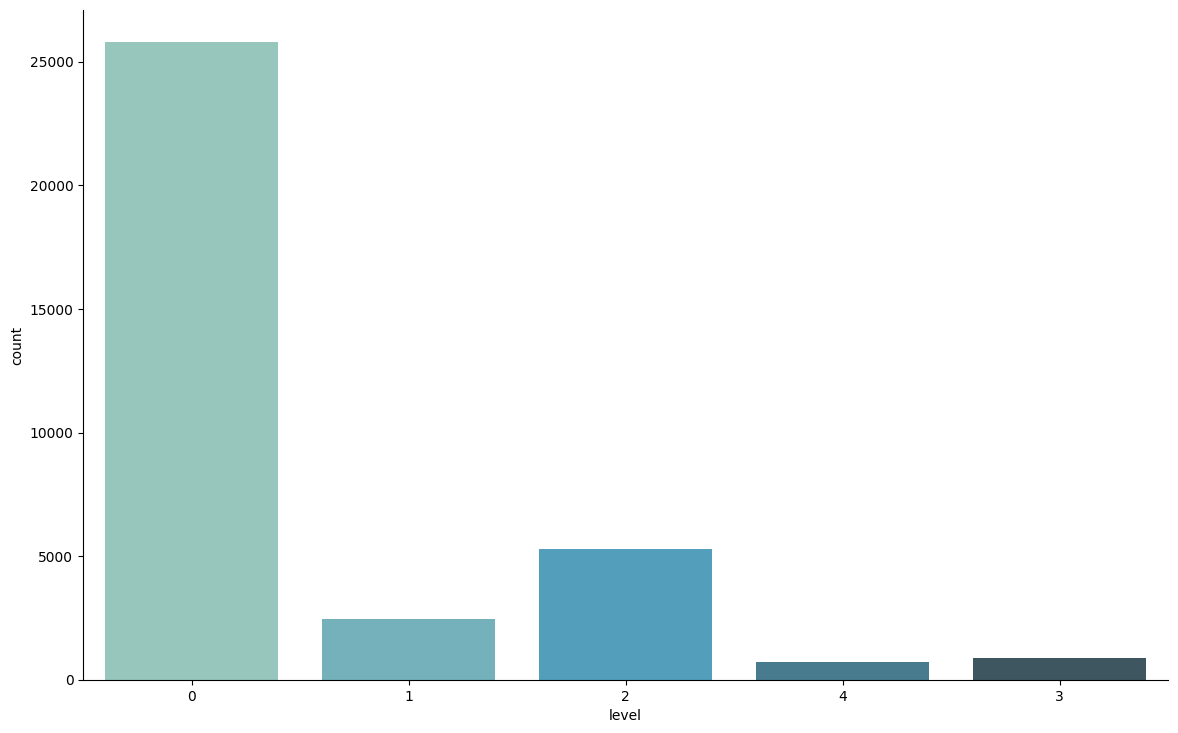

In [8]:
f, ax = plt.subplots(figsize=(14, 8.7))
ax = sns.countplot(x="level", data=labels_df, palette="GnBu_d")
sns.despine()
plt.show()

In [9]:
import cv2
sns.set_style("white")
count = 1
plt.figure(figsize=[20, 20])
for img_name in labels_df['image'][:15]:
    img = cv2.imread("resized_train/%s.jpeg" % img_name)[...,[2, 1, 0]]
    plt.subplot(5, 5, count)
    plt.imshow(img)
    plt.title("Image %s" % count)
    count += 1
    
plt.show()

TypeError: 'NoneType' object is not subscriptable

<Figure size 2000x2000 with 0 Axes>

In [15]:

# Split data into train, validation, and test sets
train_data, test_data = train_test_split(labels_df, test_size=0.2)
train_data, val_data = train_test_split(train_data, test_size=0.2)

# # Define image data augmentation and rescaling
datagen = ImageDataGenerator(
    rescale=1.0 / 255,  # Normalize pixel values to [0, 1]
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)


In [16]:
val_data

,image,level
16073,20147_right,0
35070,44268_left,0
25305,32015_right,0
4619,5812_right,0
16011,20082_right,1
...,...,...
10793,13596_right,0
12455,15612_right,0
13239,16627_right,2
33578,42420_left,1


In [18]:
train_data

,image,level
3790,4754_left,0
18445,23237_right,0
24961,31583_right,2
14943,18709_right,0
29256,37038_left,0
...,...,...
27057,34251_right,0
7464,9384_left,2
19545,24692_right,2
16573,20800_right,0


In [17]:

# Create data generators for training, validation, and testing
batch_size = 32
img_width, img_height = 224, 224  # Adjust dimensions as needed


# image_folder = 'resized_train/'  # Replace with the path to your image folder

In [19]:
# Preprocecss data
train_data["image"] = train_data["image"].apply(lambda x: x + ".jpeg")

test_data["image"] = test_data["image"].apply(lambda x: x + ".jpeg")

val_data["image"] = val_data["image"].apply(lambda x: x + ".jpeg")

train_data['level'] = train_data['level'].astype('str')
train_data.head()

,image,level
3790,4754_left.jpeg,0
18445,23237_right.jpeg,0
24961,31583_right.jpeg,2
14943,18709_right.jpeg,0
29256,37038_left.jpeg,0


In [14]:
train_datagen=ImageDataGenerator(rescale=1./255, 
                                 validation_split=0.2,
                                 horizontal_flip=True)

train_generator=datagen.flow_from_dataframe(
    dataframe=train_data,
    directory='resized_train/',  # Use the same folder for all images
    x_col='image',
    y_col='level',
    batch_size=32,
    class_mode="categorical",
    target_size=(224, 224),
    subset='training')

valid_generator=train_datagen.flow_from_dataframe(
    dataframe=val_data,
    directory='resized_train/',  # Use the same folder for all images
    x_col='image',
    y_col='level',
    batch_size=32,
    class_mode="categorical",    
    target_size=(224, 224),
    subset='validation')

test_datagen = ImageDataGenerator(rescale=1./255)

test_generator = test_datagen.flow_from_dataframe(  
        dataframe=test_data,
    directory='resized_train/',  # Use the same folder for all images
    x_col='image',
    y_col='level',
        target_size=(224, 224),
        batch_size=1,
        shuffle=False,
        class_mode=None)

Found 0 validated image filenames belonging to 0 classes.
Found 0 validated image filenames belonging to 0 classes.
Found 0 validated image filenames.


d:\codeleaf\Deep_Learning\fruit\lib\site-packages\keras\src\preprocessing\image.py:1137: UserWarning: Found 22480 invalid image filename(s) in x_col="image". These filename(s) will be ignored.
  warnings.warn(
d:\codeleaf\Deep_Learning\fruit\lib\site-packages\keras\src\preprocessing\image.py:1137: UserWarning: Found 5620 invalid image filename(s) in x_col="image". These filename(s) will be ignored.
  warnings.warn(
d:\codeleaf\Deep_Learning\fruit\lib\site-packages\keras\src\preprocessing\image.py:1137: UserWarning: Found 7026 invalid image filename(s) in x_col="image". These filename(s) will be ignored.
  warnings.warn(


In [24]:


# train_generator = datagen.flow_from_dataframe(
#     train_data,
#     directory='resized_train/',  # Use the same folder for all images
#     x_col='image',
#     y_col='level',
#     target_size=(img_width, img_height),
#     batch_size=batch_size,
#     class_mode='categorical',
#     shuffle=True
# )

# val_generator = datagen.flow_from_dataframe(
#     val_data,
#     directory='resized_train/',
#     x_col='image',
#     y_col='level',
#     target_size=(img_width, img_height),
#     batch_size=batch_size,
#     class_mode='categorical',
#     shuffle=False
# )

# test_generator = datagen.flow_from_dataframe(
#     test_data,
#     directory='resized_train/',
#     x_col='image',
#     y_col='level',
#     target_size=(img_width, img_height),
#     batch_size=batch_size,
#     class_mode='categorical',
#     shuffle=False
# )

In [25]:
model = tf.keras.Sequential([
    # Convolutional Layer 1
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(img_width, img_height, 3)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    
    # Convolutional Layer 2
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    
    # Convolutional Layer 3
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    
    # Flatten Layer
    tf.keras.layers.Flatten(),
    
    # Fully Connected Layer 1
    tf.keras.layers.Dense(128, activation='relu'),
    
    # Output Layer
    tf.keras.layers.Dense(5, activation='softmax')  # num_classes should be set according to your dataset
])

# You can customize the number of filters, filter sizes, and other hyperparameters in the convolutional layers as needed.


In [26]:
# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Train the model
epochs = 5
history = model.fit(train_generator, validation_data=valid_generator, epochs=epochs)

# Evaluate the model
test_loss, test_accuracy = model.evaluate(test_generator)


Epoch 1/5
703/703 [==============================] - 1422s 2s/step - loss: 0.8743 - accuracy: 0.7378 - val_loss: 0.9077 - val_accuracy: 0.7037
Epoch 2/5
703/703 [==============================] - 1264s 2s/step - loss: 0.8658 - accuracy: 0.7378 - val_loss: 0.9166 - val_accuracy: 0.7037
Epoch 3/5
703/703 [==============================] - 1282s 2s/step - loss: 0.8645 - accuracy: 0.7378 - val_loss: 0.9206 - val_accuracy: 0.7037
Epoch 4/5
703/703 [==============================] - 1082s 2s/step - loss: 0.8622 - accuracy: 0.7378 - val_loss: 0.9346 - val_accuracy: 0.7037
Epoch 5/5
587/703 [========================>.....] - ETA: 2:49 - loss: 0.8623 - accuracy: 0.7367

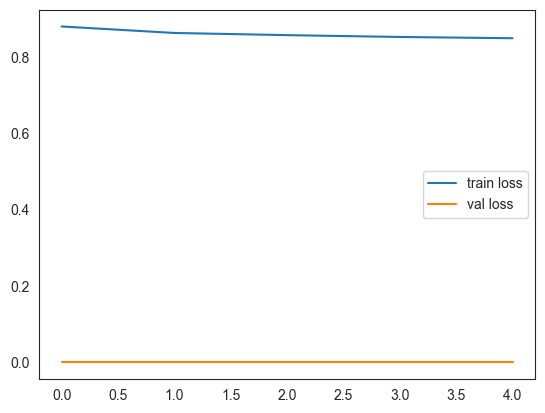

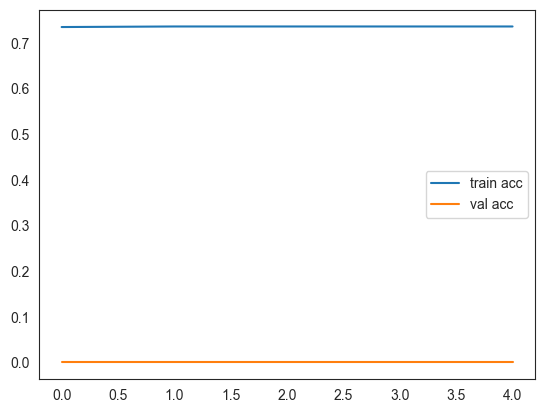

In [ ]:
# Plot the loss
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.savefig('LossVal_loss.png')  # Save the plot as an image
plt.show()

# Plot the accuracy
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.legend()
plt.savefig('AccVal_acc.png')  # Save the plot as an image
plt.show()


In [ ]:
# Print the final training and validation accuracy
final_train_accuracy = history.history['accuracy'][-1]
final_val_accuracy = history.history['val_accuracy'][-1]

print("Final Training Accuracy:", final_train_accuracy)
print("Final Validation Accuracy:", final_val_accuracy)

Final Training Accuracy: 0.7360987663269043
Final Validation Accuracy: 0.0


In [ ]:
# Assuming you have already trained the model (model.fit(...) was called)
model.save('retina.h5')


d:\codeleaf\Deep_Learning\fruit\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [16]:
from tensorflow.keras.models import load_model

# Load the model
model = load_model('model_retina.h5') # size (512,512)
# loaded_model = load_model('retina.h5')
# You can now use the loaded_model for inference or further training


In [8]:
ref = dict(zip(list(train_generator.class_indices.values()),list(train_generator.class_indices.keys())))

NameError: name 'train_generator' is not defined

In [ ]:
train_generator.class_indices

{'0': 0, '1': 1, '2': 2, '3': 3, '4': 4}

In [52]:
from tensorflow.keras.preprocessing import image
import numpy as np
from tensorflow.keras.models import load_model
from tensorflow.keras.applications.inception_v3 import preprocess_input


def prediction(path):
    # img = image.load_img(path, target_size=(224, 224))
    img = image.load_img(path, target_size=(512, 512))
    i = image.img_to_array(img)
    i = np.expand_dims(i, axis=0)
    img = preprocess_input(i)
    pred = np.argmax(model.predict(img), axis=1)
    print(f"the image belongs to {[pred[0]]}")

path = r"class 1\20.png"
prediction(path)


1/1 [==============================] - 0s 375ms/step
the image belongs to [0]


# user prediction

In [2]:
from tensorflow.keras.preprocessing import image
import numpy as np
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
import numpy as np

loaded_model = load_model('model_retina.h5')
# Assuming you have the loaded_model
def predict_image_class(image_path, loaded_model):
    img = image.load_img(image_path, target_size=(512, 512))  # Adjust target_size as needed
    img = image.img_to_array(img)
    img = np.expand_dims(img, axis=0)
    img = img / 255.0  # Normalize the image (assuming the model expects normalized input)

    # Make a prediction
    predictions = loaded_model.predict(img)
    class_index = np.argmax(predictions)
    class_probability = predictions[0][class_index]

    # Replace class_labels with your own list of class labels
    class_labels = ['class0','class1', 'class2', 'class3','class4']  
    
# 0 - No DR # 1 - Mild # 2 - Moderate # 3 - Severe # 4 - Proliferative DR

    predicted_class = class_labels[class_index]

    
    return predicted_class, class_probability

# Example usage
image_path = r"test class\class 2\5.png"

# Replace with the path to the image you want to classify
predicted_class, class_probability = predict_image_class(image_path, loaded_model)
print(f'Predicted class: {predicted_class}')
print(f'Class probability: {class_probability:.2f}')


1/1 [==============================] - 1s 1s/step
Predicted class: class2
Class probability: 0.94


1/1 [==============================] - 1s 1s/step
Predicted class: class3
Class probability: 0.60


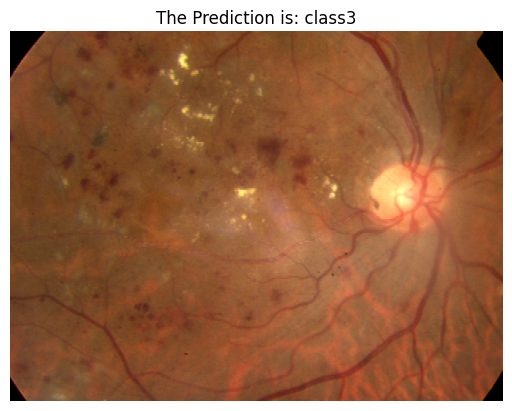

In [22]:
from tensorflow.keras.preprocessing import image
import numpy as np
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

loaded_model = load_model('model_retina.h5')

def predict_image_class(image_path, loaded_model):
    img = image.load_img(image_path, target_size=(512, 512))
    img = image.img_to_array(img)
    img = np.expand_dims(img, axis=0)
    img = img / 255.0

    predictions = loaded_model.predict(img)
    class_index = np.argmax(predictions)
    class_probability = predictions[0][class_index]

    class_labels = ['class0', 'class1', 'class2', 'class3', 'class4']
    predicted_class = class_labels[class_index]

    return predicted_class, class_probability

image_path = r"test class\class 3\11.png"

predicted_class, class_probability = predict_image_class(image_path, loaded_model)
print(f'Predicted class: {predicted_class}')
print(f'Class probability: {class_probability:.2f}')

# Read and display the image using plt.imshow
img = image.load_img(image_path)
plt.imshow(img)
plt.axis('off')
plt.title(f"The Prediction is: {predicted_class}")
plt.show()


In [ ]:
complete_datagen = ImageDataGenerator(rescale=1./255)
complete_generator = complete_datagen.flow_from_dataframe(  
        dataframe=train_data,
        directory='resized_train/',
        x_col="image",
        target_size=(224, 224),
        batch_size=1,
        shuffle=False,
        class_mode=None)

STEP_SIZE_COMPLETE = complete_generator.n//complete_generator.batch_size
train_preds = model.predict_generator(complete_generator, steps=STEP_SIZE_COMPLETE)
train_preds = [np.argmax(pred) for pred in train_preds]

Found 22480 validated image filenames.


C:\Users\deepp\AppData\Local\Temp\ipykernel_9728\2913256616.py:12: UserWarning: `Model.predict_generator` is deprecated and will be removed in a future version. Please use `Model.predict`, which supports generators.
  train_preds = model.predict_generator(complete_generator, steps=STEP_SIZE_COMPLETE)


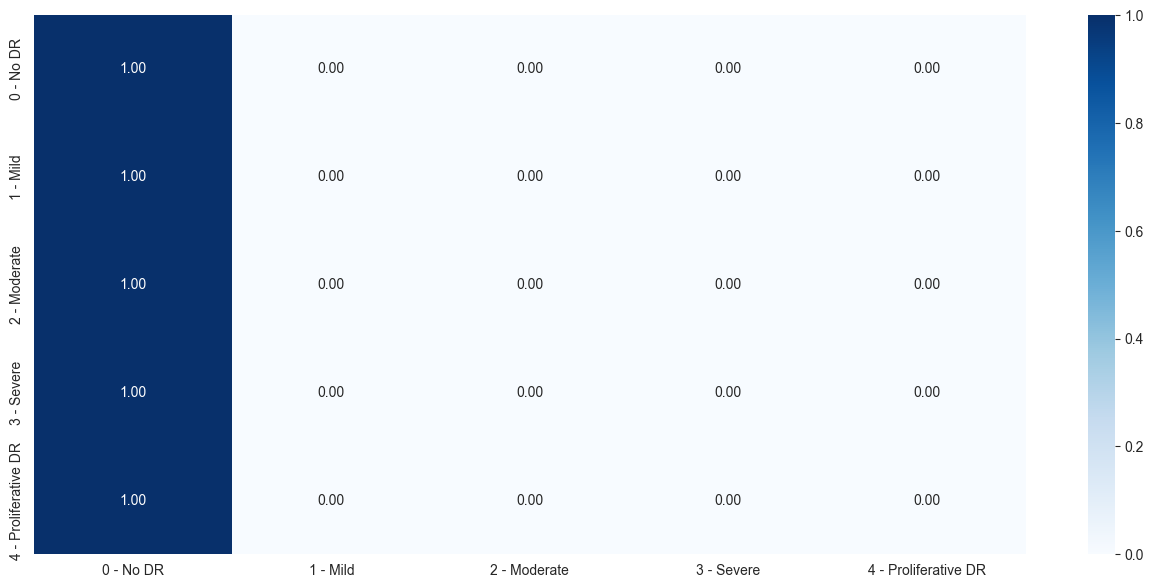

In [ ]:
from sklearn.metrics import confusion_matrix

labels = ['0 - No DR', '1 - Mild', '2 - Moderate', '3 - Severe', '4 - Proliferative DR']
cnf_matrix = confusion_matrix(train_data['level'].astype('int'), train_preds)
cnf_matrix_norm = cnf_matrix.astype('float') / cnf_matrix.sum(axis=1)[:, np.newaxis]
df_cm = pd.DataFrame(cnf_matrix_norm, index=labels, columns=labels)
plt.figure(figsize=(16, 7))
sns.heatmap(df_cm, annot=True, fmt='.2f', cmap="Blues")
plt.show()

In [ ]:
test_generator.reset()
STEP_SIZE_TEST = test_generator.n//test_generator.batch_size
preds = model.predict_generator(test_generator, steps=STEP_SIZE_TEST)
predictions = [np.argmax(pred) for pred in preds]

C:\Users\deepp\AppData\Local\Temp\ipykernel_9728\4023064720.py:3: UserWarning: `Model.predict_generator` is deprecated and will be removed in a future version. Please use `Model.predict`, which supports generators.
  preds = model.predict_generator(test_generator, steps=STEP_SIZE_TEST)


In [ ]:
filenames = test_generator.filenames
results = pd.DataFrame({'image':filenames, 'level':predictions})
results['image'] = results['image'].map(lambda x: str(x)[:-4])
# results.to_csv('submission.csv',index=False)
results.head(10)

,image,level
0,1032_left.,0
1,31675_right.,0
2,44179_right.,0
3,19478_right.,0
4,39730_right.,0
5,37594_right.,0
6,7204_right.,0
7,12655_left.,0
8,43826_right.,0
9,5725_left.,0


C:\Users\deepp\AppData\Local\Temp\ipykernel_9728\2423114711.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="level", data=results, palette="GnBu_d")


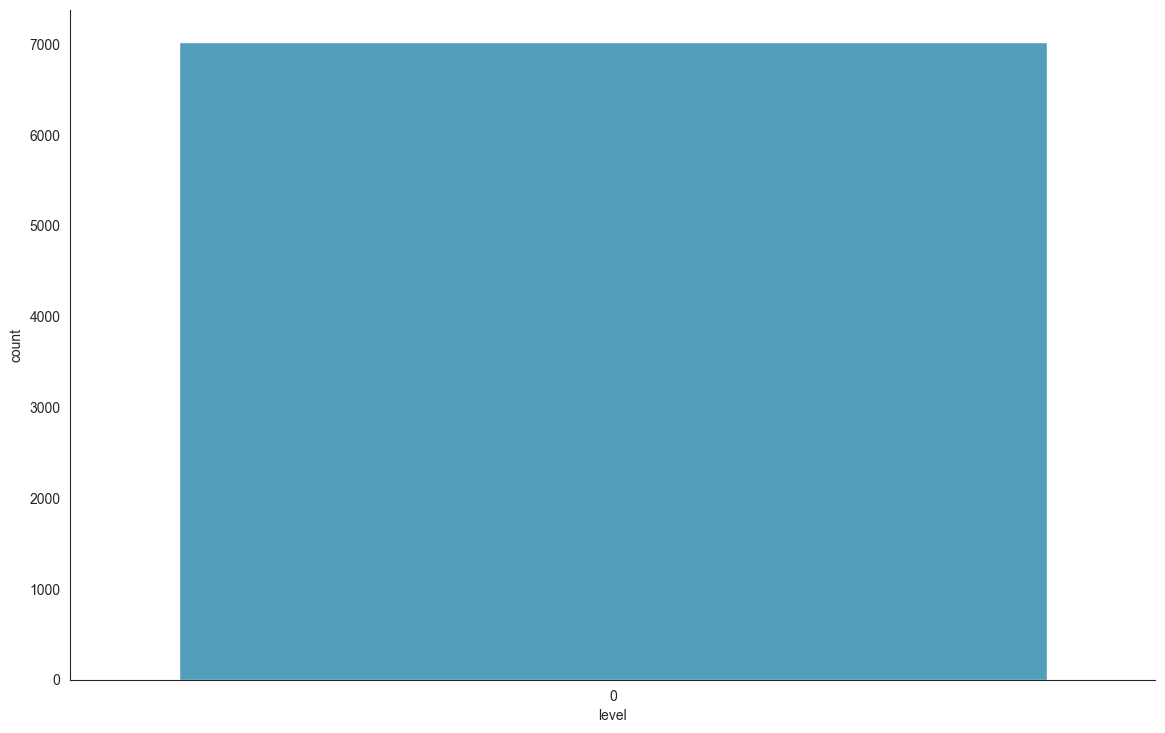

In [ ]:
f, ax = plt.subplots(figsize=(14, 8.7))
ax = sns.countplot(x="level", data=results, palette="GnBu_d")
sns.despine()
plt.show()